In [17]:
def solution(k, tangerine):
    answer = 0

    dict = {}
    # 귤 크기 별로 정리
    for t in tangerine:
        dict[t] = dict.get(t,0) + 1
    # counts = 귤 갯수 sort
    
    counts = sorted(dict.values(), reverse = True)

    # counts 에서 하나씩 pick 후 k값 비교
    # ex: counts = [2,2,2,1,1] 에서 앞의 3개 고르면 6개
    for count in counts:
        k  -= count
        answer += 1
        if k <= 0: break
        
    return answer

tangerine = [1, 3, 2, 5, 4, 5, 2, 3]
k = 6

solution(k,tangerine)



3

In [18]:
def solution(s):
    answer = ""

    for i in range(len(s)):
        if i == 0 or s[i -1] ==  " ":
            answer += s[i].upper()
        else:
            answer += s[i].lower()
    return answer
s = "3people unFollowed me"
solution(s)

'3people Unfollowed Me'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# function

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms


In [2]:
classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

In [3]:
import torch
import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

batch_size = 4

# Training dataset
trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

# Testing dataset
testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,  # Corrected: Download -> download
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2  # Corrected: num_worker -> num_workers
)

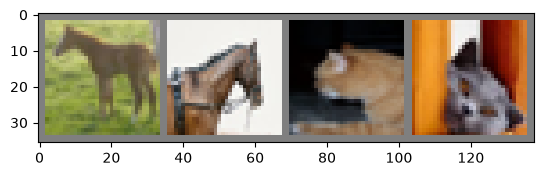

horse horse cat   cat  


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision

# Function to display an image
def imshow(img):
    img = img / 2 + 0.5  # Unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get a batch of random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Display the images
imshow(torchvision.utils.make_grid(images))

# Print the corresponding labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(len(labels))))

In [5]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5) 
        self.pool = nn.MaxPool2d(2, 2) # 2*2
        self.conv2 = nn.Conv2d(6, 16, 5) # 6을 16으로 하는 필터
        self.fc1 = nn.Linear(16 * 5 * 5, 120) # 400개
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        '''
        
        '''
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x
net = Net()

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim

# 손실 함수와 옵티마이저 정의
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    net.parameters(),
    lr=0.001,
    momentum=0.9
)

# 모델 학습
for epoch in range(2):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # 입력 이미지와 정답 레이블
        inputs, labels = data

        # 이전 단계의 기울기 초기화
        optimizer.zero_grad()

        # 순전파: 예측값 계산
        outputs = net(inputs)

        # 손실 계산
        loss = criterion(outputs, labels)

        # 역전파: 기울기 계산
        loss.backward()

        # 가중치 업데이트
        optimizer.step()

        # 손실 누적
        running_loss += loss.item()

        # 2000 미니배치마다 평균 손실 출력
        if i % 2000 == 1999:
            print(
                f'[{epoch + 1}, {i + 1:5d}] '
                f'loss: {running_loss / 2000:.3f}'
            )
            running_loss = 0.0

print('Finished Training')

[1,  2000] loss: 2.271
[1,  4000] loss: 1.864
[1,  6000] loss: 1.666
[1,  8000] loss: 1.562
[1, 10000] loss: 1.488
[1, 12000] loss: 1.436
[2,  2000] loss: 1.377
[2,  4000] loss: 1.347
[2,  6000] loss: 1.336
[2,  8000] loss: 1.320
[2, 10000] loss: 1.280
[2, 12000] loss: 1.264
Finished Training


In [7]:
PATH = './cifar_net.pth'
torch.save(net.state_dict(), PATH)

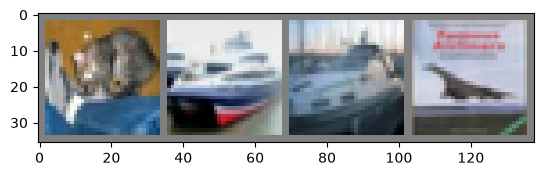

GroundTruth:  cat   ship  ship  plane


In [8]:
# 테스트 데이터에서 이미지 배치 가져오기
dataiter = iter(testloader)
images, labels = next(dataiter)

# 이미지 출력
imshow(torchvision.utils.make_grid(images))

# 실제 정답 레이블 출력
print(
    'GroundTruth: ',
    ' '.join(f'{classes[labels[j]]:5s}' for j in range(len(labels)))
)

In [9]:
net = Net()
net.load_state_dict(torch.load(PATH))
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

Predicted:  cat   ship  ship  plane
